# 02 — SpaceX Data Cleaning and Preprocessing

## Objective
Practice the initial preparation of Falcon 9 launch data: inspect missing values, duplicate rows, column types, and create a cleaned working copy.

> **Dataset path:** This notebook assumes it is run from the `notebooks/` directory and the CSV file is stored in `data/raw/`.

> This is a suggested educational continuation of Notebook 01. If you share the original course notebook #2, this notebook can be aligned to that source.

### Important note
Do not automatically remove every row with missing values or replace all missing values without inspection. The appropriate approach depends on the meaning of each column and the analysis goal.


## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## 2. Load the dataset
The relative path below is defined for running this notebook from the `notebooks/` directory.

In [2]:
file_path = "../data/raw/dataset_falcon9.csv"
df = pd.read_csv(file_path)

df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


## 3. Inspect the dataset structure

In [3]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

df.info()

Number of rows: 90
Number of columns: 18
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   FlightNumber    90 non-null     int64  
 1   Date            90 non-null     object 
 2   BoosterVersion  90 non-null     object 
 3   PayloadMass     90 non-null     float64
 4   Orbit           90 non-null     object 
 5   LaunchSite      90 non-null     object 
 6   Outcome         90 non-null     object 
 7   Flights         90 non-null     int64  
 8   GridFins        90 non-null     bool   
 9   Reused          90 non-null     bool   
 10  Legs            90 non-null     bool   
 11  LandingPad      64 non-null     object 
 12  Block           90 non-null     float64
 13  ReusedCount     90 non-null     int64  
 14  Serial          90 non-null     object 
 15  Longitude       90 non-null     float64
 16  Latitude        90 non-null     float64
 

In [4]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
FlightNumber,90.0,NaN,NaN,NaN,45.5,26.124701,1.0,23.25,45.5,67.75,90.0
Date,90,90,2010-06-04,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BoosterVersion,90,1,Falcon 9,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PayloadMass,90.0,NaN,NaN,NaN,6104.959412,4694.67172,350.0,2510.75,4701.5,8912.75,15600.0
Orbit,90,11,GTO,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LaunchSite,90,3,CCAFS SLC 40,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outcome,90,8,True ASDS,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flights,90.0,NaN,NaN,NaN,1.788889,1.213172,1.0,1.0,1.0,2.0,6.0
GridFins,90,2,True,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reused,90,2,False,53,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Check for duplicate rows

`duplicated()` identifies rows whose values match a previous row. First, count and inspect duplicates; do not remove anything yet.

In [5]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

if duplicate_count:
    display(df[df.duplicated(keep=False)].head(10))

Number of duplicate rows: 0


## 5. Check for missing values

- `isna()` identifies missing cells.
- `sum()` counts missing values in each column.
- The percentage of missing values helps compare columns.

In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
})
missing_summary = missing_summary.sort_values("missing_percent", ascending=False)
display(missing_summary)

,missing_count,missing_percent,dtype
LandingPad,26,28.89,object
FlightNumber,0,0.00,int64
Date,0,0.00,object
BoosterVersion,0,0.00,object
Orbit,0,0.00,object
PayloadMass,0,0.00,float64
Outcome,0,0.00,object
Flights,0,0.00,int64
GridFins,0,0.00,bool
LaunchSite,0,0.00,object


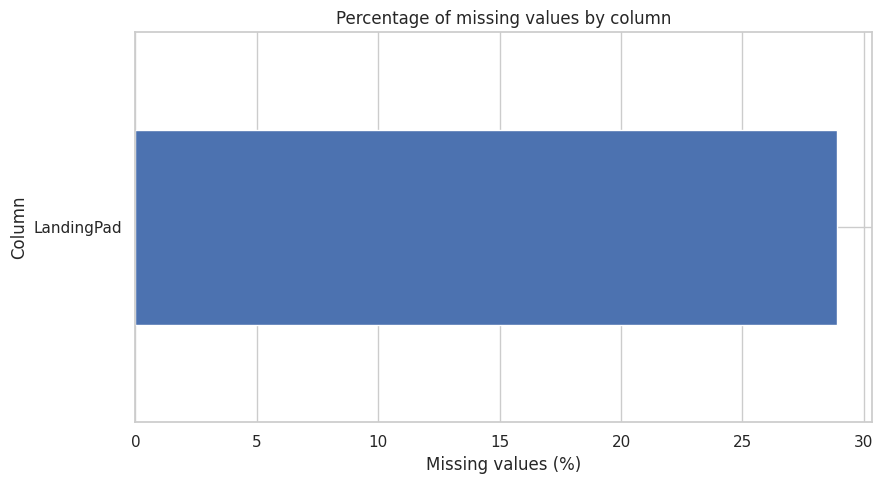

In [7]:
missing_to_plot = missing_summary[missing_summary["missing_count"] > 0]

if not missing_to_plot.empty:
    ax = missing_to_plot["missing_percent"].sort_values().plot(
        kind="barh", figsize=(9, 5), title="Percentage of missing values by column"
    )
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values were found in this dataset.")

## 6. Inspect numeric and categorical columns

Column type affects cleaning choices. For example, a mean may make sense for a numeric feature, but not for an identifier or a launch-site name.

In [8]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns:")
print(numeric_columns)

print("\nNon-numeric columns:")
print(categorical_columns)

Numeric columns:
['FlightNumber', 'PayloadMass', 'Flights', 'Block', 'ReusedCount', 'Longitude', 'Latitude', 'Class']

Non-numeric columns:
['Date', 'BoosterVersion', 'Orbit', 'LaunchSite', 'Outcome', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Serial']


## 7. Inspect unique values in categorical columns

This can help identify unexpected categories, leading or trailing spaces, or inconsistent value formatting.

In [9]:
for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(f"Number of unique values: {df[column].nunique(dropna=True)}")
    display(df[column].value_counts(dropna=False).head(15).to_frame("count"))


--- Date ---
Number of unique values: 90


,count
Date,
2010-06-04,1
2012-05-22,1
2013-03-01,1
2013-09-29,1
2013-12-03,1
2014-01-06,1
2014-04-18,1
2014-07-14,1
2014-08-05,1



--- BoosterVersion ---
Number of unique values: 1


,count
BoosterVersion,
Falcon 9,90



--- Orbit ---
Number of unique values: 11


...

,count
Legs,
True,71
False,19



--- LandingPad ---
Number of unique values: 5


,count
LandingPad,
5e9e3032383ecb6bb234e7ca,35
NaN,26
5e9e3032383ecb267a34e7c7,13
5e9e3033383ecbb9e534e7cc,12
5e9e3032383ecb761634e7cb,2
5e9e3032383ecb554034e7c9,2



--- Serial ---
Number of unique values: 53


,count
Serial,
B1049,6
B1051,5
B1046,4
B1048,4
B1059,4
B1056,4
B1047,3
B1058,3
B1060,3


## 8. Create a working copy

Keep the raw data unchanged and perform cleaning on a copy. At this stage, only remove leading and trailing spaces from column names; no rows are removed and missing values are not imputed.

In [10]:
df_clean = df.copy()

df_clean.columns = df_clean.columns.str.strip()

print("Raw data shape:", df.shape)
print("Working copy shape:", df_clean.shape)
print("Column names:")
print(df_clean.columns.tolist())

Raw data shape: (90, 18)
Working copy shape: (90, 18)
Column names:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']


## 9. Remove duplicate rows (optional)

If inspection confirms that duplicate rows are genuinely duplicated records, you can remove them. The cell below modifies the working copy, not the original `df`. Do not run this step if repeated rows are meaningful in your data.

In [11]:
df_clean = df_clean.drop_duplicates().copy()

print(f"Rows after removing duplicates: {len(df_clean)}")
print(f"Remaining duplicate rows: {df_clean.duplicated().sum()}")

Rows after removing duplicates: 90
Remaining duplicate rows: 0


## 10. Decide how to handle missing values

This section creates a summary of missing values in the working copy. The final strategy (dropping rows, filling with the median/mean, or using a dedicated category) should depend on the column's meaning and the analysis goal.

In [12]:
missing_after = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (df_clean.isna().mean() * 100).round(2),
})
display(missing_after[missing_after["missing_count"] > 0].sort_values(
    "missing_percent", ascending=False
))

,missing_count,missing_percent
LandingPad,26,28.89


## 11. Save the cleaned dataset (optional)

This cell saves the file to `data/processed/`. It creates the directory if it does not exist. Run this cell only if you want to save the output CSV.

In [13]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "dataset_falcon9_cleaned.csv"
df_clean.to_csv(output_path, index=False)

print(f"File saved to: {output_path}")

File saved to: ../data/processed/dataset_falcon9_cleaned.csv


## 12. Exercises

1. Which column has the highest percentage of missing values?
2. Should every duplicate row be removed? Explain your reasoning.
3. What method could be appropriate for handling missing values in `PayloadMass`? Why?
4. Choose a categorical column and inspect its unique values.
5. How did the dataset's `shape` change after cleaning? Explain why.

## Summary

- Inspect the raw data before cleaning.
- Remove or replace data only for a clear reason.
- Keep raw and processed data separate.
